In [1]:
import pandas as pd
df=pd.read_csv("loan_approval_dataset.csv")
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [2]:
df.isnull().sum()

loan_id                      0
 no_of_dependents            0
 education                   0
 self_employed               0
 income_annum                0
 loan_amount                 0
 loan_term                   0
 cibil_score                 0
 residential_assets_value    0
 commercial_assets_value     0
 luxury_assets_value         0
 bank_asset_value            0
 loan_status                 0
dtype: int64

In [3]:
df.duplicated().sum()

np.int64(0)

In [7]:
print(df.columns.tolist())

['loan_id', ' no_of_dependents', ' education', ' self_employed', ' income_annum', ' loan_amount', ' loan_term', ' cibil_score', ' residential_assets_value', ' commercial_assets_value', ' luxury_assets_value', ' bank_asset_value', ' loan_status']


In [8]:
df.columns = df.columns.str.strip()
cat_col=["education","self_employed","loan_status"]
df[cat_col]=df[cat_col].astype("category")

In [9]:
# Encode binary categorical input features
df['education'] = df['education'].map({
    ' Not Graduate': 0,
    ' Graduate': 1
})

df['self_employed'] = df['self_employed'].map({
    ' No': 0,
    ' Yes': 1
})

# Encode target variable
df['loan_status'] = df['loan_status'].map({
    ' Rejected': 0,
    ' Approved': 1
})

In [10]:
df.isnull().sum()

loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64

In [11]:
# Independent variables (features)
X = df.drop('loan_status', axis=1)

# Dependent variable (target)
y = df['loan_status']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Features shape: (4269, 12)
Target shape: (4269,)


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
0,1,2,1,0,9600000,29900000,12,778,2400000,17600000,22700000,8000000
1,2,0,0,1,4100000,12200000,8,417,2700000,2200000,8800000,3300000
2,3,3,1,0,9100000,29700000,20,506,7100000,4500000,33300000,12800000
3,4,3,1,0,8200000,30700000,8,467,18200000,3300000,23300000,7900000
4,5,5,0,1,9800000,24200000,20,382,12400000,8200000,29400000,5000000


0    1
1    0
2    0
3    0
4    0
Name: loan_status, dtype: category
Categories (2, int64): [1, 0]

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training features: (3415, 12)
Testing features: (854, 12)

Training target distribution:
loan_status
1    0.622255
0    0.377745
Name: proportion, dtype: float64

Testing target distribution:
loan_status
1    0.62178
0    0.37822
Name: proportion, dtype: float64


In [13]:
from sklearn.tree import DecisionTreeClassifier

# Create the model
dt_model = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

# Train the model
dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [14]:
# Predict loan approval on test data
y_pred_dt = dt_model.predict(X_test)

print("Actual values:")
print(y_test.head(10).values)

print("\nPredicted values:")
print(y_pred_dt[:10])

Actual values:
[0, 0, 0, 1, 1, 1, 1, 0, 1, 0]
Categories (2, int64): [1, 0]

Predicted values:
[1 0 0 1 1 1 1 0 1 0]


Decision Tree Evaluation
------------------------
Accuracy: 0.9800936768149883
Precision: 0.9830827067669173
Recall: 0.9849340866290018
F1 Score: 0.9840075258701787

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.97      0.97       323
           1       0.98      0.98      0.98       531

    accuracy                           0.98       854
   macro avg       0.98      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854



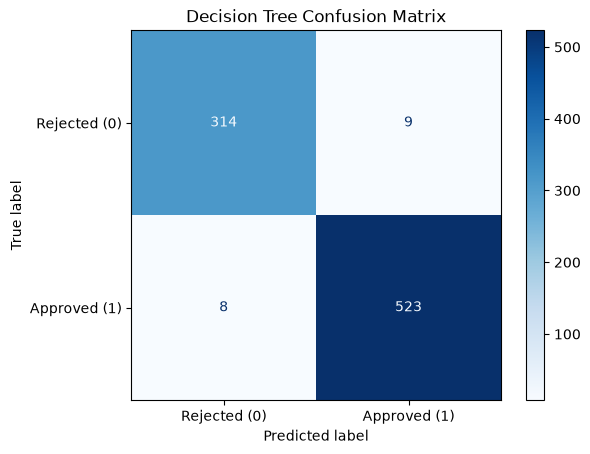

In [15]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Calculate evaluation metrics
print("Decision Tree Evaluation")
print("------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("F1 Score:", f1_score(y_test, y_pred_dt))

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_dt)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Rejected (0)', 'Approved (1)']
)

disp.plot(cmap='Blues')
plt.title("Decision Tree Confusion Matrix")
plt.show()

In [16]:
from sklearn.naive_bayes import GaussianNB

# Create Naive Bayes model
nb_model = GaussianNB()

# Train the model
nb_model.fit(X_train, y_train)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [17]:
y_pred_nb = nb_model.predict(X_test)

print("Actual values:")
print(y_test.head(10).values)

print("\nPredicted values:")
print(y_pred_nb[:10])

Actual values:
[0, 0, 0, 1, 1, 1, 1, 0, 1, 0]
Categories (2, int64): [1, 0]

Predicted values:
[1 1 1 1 1 1 1 1 1 0]


Naive Bayes Evaluation
----------------------
Accuracy: 0.7576112412177985
Precision: 0.7262569832402235
Recall: 0.9792843691148776
F1 Score: 0.8340016038492382

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.39      0.55       323
           1       0.73      0.98      0.83       531

    accuracy                           0.76       854
   macro avg       0.82      0.69      0.69       854
weighted avg       0.80      0.76      0.73       854



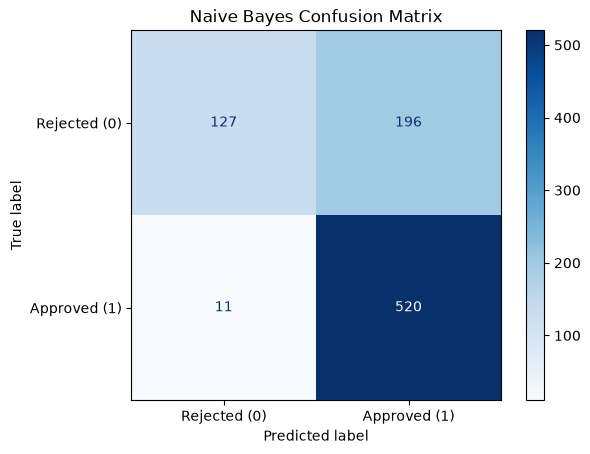

In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

print("Naive Bayes Evaluation")
print("----------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print("Precision:", precision_score(y_test, y_pred_nb))
print("Recall:", recall_score(y_test, y_pred_nb))
print("F1 Score:", f1_score(y_test, y_pred_nb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))

cm_nb = confusion_matrix(y_test, y_pred_nb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=['Rejected (0)', 'Approved (1)']
)

disp.plot(cmap='Blues')
plt.title("Naive Bayes Confusion Matrix")
plt.show()

In [19]:
comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],

    'Decision Tree': [
        accuracy_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_dt)
    ],

    'Naive Bayes': [
        accuracy_score(y_test, y_pred_nb),
        precision_score(y_test, y_pred_nb),
        recall_score(y_test, y_pred_nb),
        f1_score(y_test, y_pred_nb)
    ]
})

display(comparison.round(4))

,Metric,Decision Tree,Naive Bayes
0,Accuracy,0.9801,0.7576
1,Precision,0.9831,0.7263
2,Recall,0.9849,0.9793
3,F1 Score,0.9840,0.8340
